# Streamfunction Inversion: T-point vs X-point Placement

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/streamfunction_inversion.ipynb)

The vorticity–streamfunction relation $\nabla^2 \psi = \zeta$ is the canonical elliptic inversion in geophysical fluid dynamics. On the Arakawa C-grid, the **same physical equation** requires **different spectral solvers** depending on where $\psi$ lives:

| Placement | Grid type | Solver | API |
|-----------|-----------|--------|-----|
| X-points (corners) | Regular (vertex-centred) | DST-I on X `[1:-2, 1:-2]` | `gfd.streamfunction_from_vorticity(bc="dst")` |
| T-points (cell centres) | Staggered (cell-centred) | DST-II | `gridax_jax.solve_poisson_dst2` (direct) |

## Where does $\psi$ live?

```
  Option A: ψ at X-points (corners)     Option B: ψ at T-points (centres)
  ─────────────────────────────────      ──────────────────────────────────

  ψ ── · ── ψ ── · ── ψ                · ── · ── · ── · ── ·
  |         |         |                  |         |         |
  ·    ζ    ·    ζ    ·                  ·    ψ    ·    ψ    ·
  |         |         |                  |    ζ    |    ζ    |
  ψ ── · ── ψ ── · ── ψ                · ── · ── · ── · ── ·
  |         |         |                  |         |         |
  ·    ζ    ·    ζ    ·                  ·    ψ    ·    ψ    ·
  |         |         |                  |    ζ    |    ζ    |
  ψ ── · ── ψ ── · ── ψ                · ── · ── · ── · ── ·

  ψ at corners, ζ at centres             ψ and ζ co-located at centres
  Solver: DST-I (regular Dirichlet)      Solver: DST-II (staggered Dirichlet)
```

This notebook compares both placements on a Lamb–Oseen vortex test case. The X-point inversion is [`streamfunction_from_vorticity`](xref:api#sesmax_core.streamfunction_from_vorticity) from sesmax; the grid, the difference and interpolation operators and the T-point solver are gridax's.

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import warnings

import gridax
import gridax_jax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import sesmax_core.gfd as gfd


warnings.filterwarnings("ignore", message=r".*IProgress.*")
jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p numpy,matplotlib,jax,gridax,gridax_jax,sesmax_core",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

numpy      : 2.4.4
matplotlib : 3.11.2
jax        : 0.12.0.1
gridax     : 0.2.0
gridax_jax : 0.3.0
sesmax_core: 0.1.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Analytical Vortex (Lamb–Oseen)

We use a Gaussian vorticity field centred in a rectangular basin with $\psi = 0$ on the walls:

$$\zeta(x, y) = \frac{\Gamma}{\pi r_0^2} \exp\!\left(-\frac{r^2}{r_0^2}\right)$$

where $r^2 = (x - x_0)^2 + (y - y_0)^2$.

In [4]:
nx, ny = 128, 128
Lx, Ly = 2e6, 2e6  # 2000 km × 2000 km basin

grid = gridax.CartesianGrid2D.from_interior(nx, ny, Lx, Ly)
dx, dy = grid.dx, grid.dy

# Vortex parameters
Gamma = 1e5  # circulation (m²/s)
r0 = 300e3  # vortex radius (300 km)
x0, y0 = Lx / 2, Ly / 2  # centre of domain

# We construct ζ at the two C-grid locations, on the full [Ny, Nx] arrays
# of the grid (ghost ring included):
#
# - X-points (corners): X[j, i] sits at (x, y) = (i dx, j dy); the walls are
#   the X nodes 0 and N-2 (x = 0 and x = Lx), index N-1 is outside.  The
#   wrapper solves the wet nodes [1:-2, 1:-2] with ψ = 0 on the wall nodes.
# - T-points (cell centres): T[j, i] sits at ((i - 1/2) dx, (j - 1/2) dy);
#   the interior is [1:-1, 1:-1] and the walls are the faces half a cell
#   outside it (DST-II).

# X-point coordinates on the full array
x_X = jnp.arange(nx + 2)[None, :] * dx
y_X = jnp.arange(ny + 2)[:, None] * dy

# T-point coordinates of the interior cells
x_T = (jnp.arange(nx)[None, :] + 0.5) * dx
y_T = (jnp.arange(ny)[:, None] + 0.5) * dy

# Vorticity on each grid
r2_X = (x_X - x0) ** 2 + (y_X - y0) ** 2
zeta_X = (Gamma / (jnp.pi * r0**2)) * jnp.exp(-r2_X / r0**2)

r2_T = (x_T - x0) ** 2 + (y_T - y0) ** 2
zeta_T = (Gamma / (jnp.pi * r0**2)) * jnp.exp(-r2_T / r0**2)

print(f"max |ζ_X| = {float(jnp.abs(zeta_X).max()):.4e} s⁻¹ (vertex grid)")
print(f"max |ζ_T| = {float(jnp.abs(zeta_T).max()):.4e} s⁻¹ (cell-centre grid)")

max |ζ_X| = 3.5368e-07 s⁻¹ (vertex grid)
max |ζ_T| = 3.5320e-07 s⁻¹ (cell-centre grid)


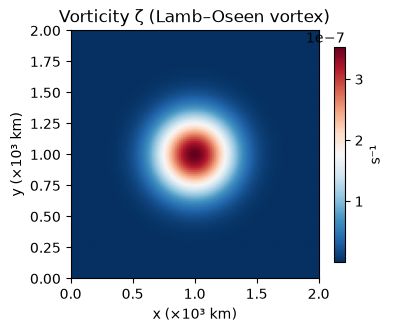

In [5]:
fig, ax = plt.subplots(figsize=(4, 3.5))
im = ax.imshow(
    np.asarray(zeta_T),
    origin="lower",
    cmap="RdBu_r",
    extent=[0, Lx / 1e6, 0, Ly / 1e6],
)
ax.set_xlabel("x (×10³ km)")
ax.set_ylabel("y (×10³ km)")
ax.set_title("Vorticity ζ (Lamb–Oseen vortex)")
fig.colorbar(im, ax=ax, shrink=0.8, label="s⁻¹")
plt.show()

## 2. X-point Inversion (DST-I)

The sesmax wrapper [`streamfunction_from_vorticity`](xref:api#sesmax_core.streamfunction_from_vorticity) puts $\psi$ at the X-points (corners).  We pass the full `[Ny, Nx]` array: it solves the wet X nodes `[1:-2, 1:-2]` with DST-I, so that $\psi = 0$ falls exactly on the wall nodes `0` and `N-2`, and returns zeros there.

In [6]:
psi_X_full = gfd.streamfunction_from_vorticity(zeta_X, dx, dy, bc="dst")
psi_X = psi_X_full[1:-2, 1:-2]  # wet X nodes, for plotting

print(f"ψ_X range: [{float(psi_X.min()):.2e}, {float(psi_X.max()):.2e}]")

ψ_X range: [-2.50e+04, -6.68e+00]


## 3. T-point Inversion (DST-II)

For $\psi$ co-located with $\zeta$ at T-points (cell centres), we use the staggered Dirichlet solver directly.

In [7]:
psi_T = gridax_jax.solve_poisson_dst2(zeta_T, dx, dy)

print(f"ψ_T range: [{float(psi_T.min()):.2e}, {float(psi_T.max()):.2e}]")

ψ_T range: [-2.50e+04, -1.67e+00]


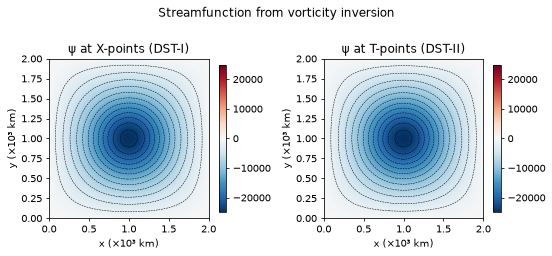

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), dpi=70)

vmax = max(float(jnp.abs(psi_X).max()), float(jnp.abs(psi_T).max()))

for ax, psi, title in zip(
    axes,
    [psi_X, psi_T],
    ["ψ at X-points (DST-I)", "ψ at T-points (DST-II)"],
    strict=True,
):
    im = ax.imshow(
        np.asarray(psi),
        origin="lower",
        cmap="RdBu_r",
        extent=[0, Lx / 1e6, 0, Ly / 1e6],
        vmin=-vmax,
        vmax=vmax,
    )
    ny_p, nx_p = psi.shape
    X_plot = np.linspace(0, Lx / 1e6, nx_p)
    Y_plot = np.linspace(0, Ly / 1e6, ny_p)
    ax.contour(X_plot, Y_plot, np.asarray(psi), levels=12, colors="k", linewidths=0.5)
    ax.set_xlabel("x (×10³ km)")
    ax.set_ylabel("y (×10³ km)")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle("Streamfunction from vorticity inversion", y=1.02)
fig.tight_layout()
plt.show()

## 4. Velocity Recovery

From each $\psi$ placement, we recover $(u, v)$ using C-grid differences.

**From $\psi$ at X-points (corners):**
- $u = -\partial\psi/\partial y$ at U-points via `diff_y_X_to_U` (natural X→U map)
- $v = +\partial\psi/\partial x$ at V-points via `diff_x_X_to_V` (natural X→V map)

**From $\psi$ at T-points (cell centres):**
- `Difference2D.grad_perp(psi)` returns $(u, v)$ at (U, V) points directly,   combining interpolation and differentiation in the correct staggered sense.

In [9]:
# psi_X_full is already on the full grid (wall nodes and outside index zero).
# Pad the T-point solution into the full grid (with ghost ring)
psi_T_full = jnp.zeros((ny + 2, nx + 2))
psi_T_full = psi_T_full.at[1:-1, 1:-1].set(psi_T)

diff_op = gridax.Difference2D(grid)

# From ψ at X-points: use dedicated X→U and X→V operators
u_from_X = -diff_op.diff_y_X_to_U(psi_X_full)
v_from_X = diff_op.diff_x_X_to_V(psi_X_full)

# From ψ at T-points: use perpendicular gradient (u at U, v at V)
u_from_T, v_from_T = diff_op.grad_perp(psi_T_full)

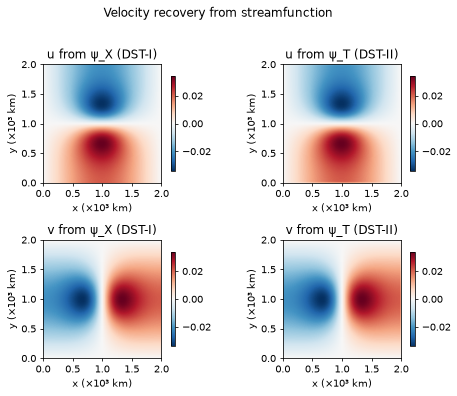

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5.5), dpi=70)

fields = [
    (u_from_X, "u from ψ_X (DST-I)"),
    (u_from_T, "u from ψ_T (DST-II)"),
    (v_from_X, "v from ψ_X (DST-I)"),
    (v_from_T, "v from ψ_T (DST-II)"),
]

for ax, (field, title) in zip(axes.flat, fields, strict=True):
    f = np.asarray(field[1:-1, 1:-1])
    vmax_f = np.abs(f).max()
    im = ax.imshow(
        f,
        origin="lower",
        cmap="RdBu_r",
        extent=[0, Lx / 1e6, 0, Ly / 1e6],
        vmin=-vmax_f,
        vmax=vmax_f,
    )
    ax.set_title(title)
    ax.set_xlabel("x (×10³ km)")
    ax.set_ylabel("y (×10³ km)")
    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle("Velocity recovery from streamfunction", y=1.02)
fig.tight_layout()
plt.show()

## 5. Error Analysis

The two placements sample $\psi$ half a cell apart, so we average the X-point solution to the T-points before comparing; both solve the same basin, so the difference is the $O(dx^2)$ discretisation error.

In [11]:
interp_op = gridax.Interpolation2D(grid)
psi_X_on_T = interp_op.X_to_T(psi_X_full)[1:-1, 1:-1]
diff_psi = jnp.abs(psi_X_on_T - psi_T)
print(f"max |ψ_X - ψ_T| = {float(diff_psi.max()):.4e}")
print(f"relative diff   = {float(diff_psi.max() / jnp.abs(psi_T).max()):.4e}")

max |ψ_X - ψ_T| = 1.0782e+01
relative diff   = 4.3207e-04


### Convergence test

We verify that both placements converge at $O(dx^2)$ against a manufactured solution $\psi_{\text{exact}} = \sin(\pi x / L_x) \sin(\pi y / L_y)$ which satisfies $\psi = 0$ on the walls $x = 0, L_x$ and $y = 0, L_y$, sampled at each placement's own points.

In [12]:
resolutions = [16, 32, 64, 128, 256]
errors_dst1 = []
errors_dst2 = []
k2 = (jnp.pi / Lx) ** 2 + (jnp.pi / Ly) ** 2  # ∇²ψ_exact = -k2 ψ_exact

for N in resolutions:
    dx_n = Lx / N
    dy_n = Ly / N

    # X-points on the full [N+2, N+2] array: x = i dx, wall nodes 0 and N.
    x_n = jnp.arange(N + 2)[None, :] * dx_n
    y_n = jnp.arange(N + 2)[:, None] * dy_n
    psi_exact_X = jnp.sin(jnp.pi * x_n / Lx) * jnp.sin(jnp.pi * y_n / Ly)
    psi_dst1 = gfd.streamfunction_from_vorticity(
        -k2 * psi_exact_X, dx_n, dy_n, bc="dst"
    )
    # Error on the wet X nodes [1:-2, 1:-2]
    errors_dst1.append(
        float(jnp.abs(psi_dst1[1:-2, 1:-2] - psi_exact_X[1:-2, 1:-2]).max())
    )

    # T-points (interior cells): x = (i + 1/2) dx, walls on the faces.
    x_c = (jnp.arange(N)[None, :] + 0.5) * dx_n
    y_c = (jnp.arange(N)[:, None] + 0.5) * dy_n
    psi_exact_T = jnp.sin(jnp.pi * x_c / Lx) * jnp.sin(jnp.pi * y_c / Ly)
    psi_dst2 = gridax_jax.solve_poisson_dst2(-k2 * psi_exact_T, dx_n, dy_n)
    errors_dst2.append(float(jnp.abs(psi_dst2 - psi_exact_T).max()))

In [13]:
for name, errs in [("DST-I", errors_dst1), ("DST-II", errors_dst2)]:
    orders = np.log2(np.array(errs[:-1]) / np.array(errs[1:]))
    print(name, "errors:", [f"{e:.2e}" for e in errs])
    print(name, "observed orders:", [f"{o:.2f}" for o in orders])

DST-I errors: ['3.22e-03', '8.04e-04', '2.01e-04', '5.02e-05', '1.25e-05']
DST-I observed orders: ['2.00', '2.00', '2.00', '2.00']
DST-II errors: ['3.19e-03', '8.02e-04', '2.01e-04', '5.02e-05', '1.25e-05']
DST-II observed orders: ['1.99', '2.00', '2.00', '2.00']


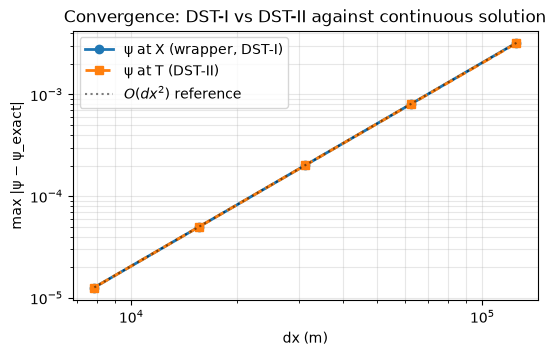

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))

dxs = [Lx / N for N in resolutions]
ax.loglog(dxs, errors_dst1, "o-", label="ψ at X (wrapper, DST-I)", lw=2)
ax.loglog(dxs, errors_dst2, "s--", label="ψ at T (DST-II)", lw=2)

# Reference O(dx²) line
dx_ref = np.array(dxs)
ref = errors_dst1[0] * (dx_ref / dx_ref[0]) ** 2
ax.loglog(dx_ref, ref, "k:", alpha=0.5, label="$O(dx^2)$ reference")

ax.set_xlabel("dx (m)")
ax.set_ylabel("max |ψ − ψ_exact|")
ax.set_title("Convergence: DST-I vs DST-II against continuous solution")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

Both placements converge at **second order** ($O(dx^2)$) because each solver's implicit zero sits on the wall: DST-I on the X wall nodes, DST-II on the cell faces.  The spectral solvers invert the discrete $[1,-2,1]/dx^2$ Laplacian exactly, but the RHS was computed from the *continuous* $\nabla^2$, so that $O(dx^2)$ gap is the error.  (Passing the T-point interior to DST-I instead would put the wall half a cell outside and drop to first order.)

## 6. When to Use Which

| | ψ at X-points (DST-I) | ψ at T-points (DST-II) |
|---|---|---|
| **Natural for** | Vorticity–streamfunction formulation | Pressure-like formulations |
| **Velocity recovery** | Direct difference X→U, X→V | T→U, T→V (same as pressure gradient) |
| **BC enforcement** | ψ=0 on the X wall nodes (on the boundary) | ψ=0 on the cell faces (half a spacing outside the T points) |
| **API** | [`streamfunction_from_vorticity`](xref:api#sesmax_core.streamfunction_from_vorticity) with `bc="dst"` | Direct `gridax_jax.solve_poisson_dst2` |
| **Typical use case** | QG models, barotropic vorticity | Projection methods, SSH diagnostics |